# 07 — Building-type dataset construction

**Research brief.** Construct a labeled dataset covering functional building categories, then associate each building with its AlphaEarth representation.

| Brief category | Study label(s) | Overture `class` (high-precision) |
|---|---|---|
| Single-family residential | `single_family` | house, detached, bungalow, semi, semidetached_house |
| Multi-family residential | `multi_family` | apartments, dormitory |
| Schools | `education` | school, kindergarten, college, university |
| Hospitals | `medical` | hospital, clinic |
| Commercial or office | `retail`, `office` | retail, commercial, supermarket / office |
| Additional (label quality) | hotel, industrial, religious, civic | see `CLASS_TO_LABEL` |

**Label source (v1).** Overture Maps buildings (`class` from OSM). Ambiguous tags (`residential`, `terrace`, bare `building=yes`) are excluded.

**Embeddings.** AlphaEarth Satellite Embedding V1, calendar **2024**, **64-D** at footprint centroid.

**Canonical outputs.** `outputs/building_type_dataset/` (built by `scripts/build_building_type_dataset.py`).

**Requires.** Network for Overture if rebuilding labels; EE auth + `EE_PROJECT` if rebuilding embeddings. Loading the saved dataset needs only pandas/pyarrow.


## Setup

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

OUT = ROOT / "outputs" / "building_type_dataset"
BANDS = [f"A{i:02d}" for i in range(64)]
LABEL_ORDER = [
    "single_family", "multi_family", "education", "medical", "retail",
    "office", "hotel", "industrial", "religious", "civic",
]

print("ROOT:", ROOT)
print("OUT:", OUT)
print("dataset exists:", (OUT / "dataset.parquet").exists())


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_type_dataset
dataset exists: True


## 1. Build or load the dataset

Prefer the saved parquet. To regenerate from Overture + Earth Engine:

```bash
python scripts/build_building_type_dataset.py                 # promote/reuse caches
python scripts/build_building_type_dataset.py --rebuild-labels
python scripts/build_building_type_dataset.py --rebuild-embeddings
```


In [2]:
dataset_path = OUT / "dataset.parquet"
if not dataset_path.exists():
    raise FileNotFoundError(
        f"Missing {dataset_path}. Run: python scripts/build_building_type_dataset.py"
    )

df = pd.read_parquet(dataset_path)
manifest = json.loads((OUT / "manifest.json").read_text())
gaps = json.loads((OUT / "gaps.json").read_text())

print("n buildings:", len(df))
print("regions:", sorted(df["region"].unique()))
print("embedding year:", manifest["embedding"]["year"])
print("feature matrix:", df[BANDS].shape)
assert df[BANDS].notna().all().all()
df[["id", "region", "class", "label", "brief_category", "lon", "lat", "height"]].head()


n buildings: 11280
regions: ['Atlanta_SE', 'Boston_NE', 'Chicago_MW', 'Denver_W', 'Houston_S', 'LA_W', 'NYC_NE', 'Phoenix_SW', 'SF_W', 'Seattle_NW']
embedding year: 2024
feature matrix: (11280, 64)


,id,region,class,label,brief_category,lon,lat,height
0,b1b2cd95-8fc4-4696-a969-deeb58f4880e,Boston_NE,cathedral,religious,Additional — religious,-71.070,42.341,30.900
1,27a715f5-554f-4dc7-8fc1-8b99a868eac4,Boston_NE,synagogue,religious,Additional — religious,-71.094,42.349,21.400
2,4f545da6-5591-4219-aa39-4b753d4e44cb,Boston_NE,synagogue,religious,Additional — religious,-71.109,42.340,11.800
3,8e328eef-43e6-440b-ac07-fee253dd264b,Boston_NE,synagogue,religious,Additional — religious,-71.126,42.344,25.500
4,19af6b04-00a9-406e-8e77-9fe94f64ecd9,Boston_NE,synagogue,religious,Additional — religious,-71.153,42.340,10.800


## 2. Category coverage (research brief ↔ study labels)


In [3]:
brief = (
    df.groupby("brief_category", sort=False)
    .agg(n=("id", "size"), study_labels=("label", lambda s: ", ".join(sorted(s.unique()))))
    .reindex(
        [
            "Single-family residential",
            "Multi-family residential",
            "Schools",
            "Hospitals",
            "Commercial or office",
            "Additional — hotel",
            "Additional — industrial",
            "Additional — religious",
            "Additional — civic",
        ]
    )
)
print("=== Research-brief categories ===")
display(brief)

print("\n=== Study labels ===")
counts = df["label"].value_counts().reindex(LABEL_ORDER).fillna(0).astype(int)
display(counts.to_frame("n"))

by_region = (
    df.groupby(["region", "label"]).size().unstack(fill_value=0).reindex(columns=LABEL_ORDER)
)
by_region.to_csv(OUT / "label_counts_by_region.csv")
by_region


=== Research-brief categories ===


,n,study_labels
brief_category,,
Single-family residential,1987,single_family
Multi-family residential,1102,multi_family
Schools,1840,education
Hospitals,594,medical
Commercial or office,2372,"office, retail"
Additional — hotel,539,hotel
Additional — industrial,1287,industrial
Additional — religious,802,religious
Additional — civic,757,civic



=== Study labels ===


,n
label,
single_family,1987
multi_family,1102
education,1840
medical,594
retail,1616
office,756
hotel,539
industrial,1287
religious,802


label,single_family,multi_family,education,medical,retail,office,hotel,industrial,religious,civic
region,,,,,,,,,,
Atlanta_SE,181,137,205,34,162,80,36,84,73,26
Boston_NE,244,160,219,80,167,80,64,157,100,99
Chicago_MW,235,114,191,79,160,80,80,139,99,144
Denver_W,232,84,160,37,163,80,35,114,82,139
Houston_S,229,96,164,56,161,80,49,163,83,90
LA_W,92,93,245,80,160,36,80,160,57,24
NYC_NE,184,153,191,80,161,80,80,160,112,126
Phoenix_SW,228,80,179,60,161,80,55,103,86,48
SF_W,122,81,114,31,160,80,37,100,42,38


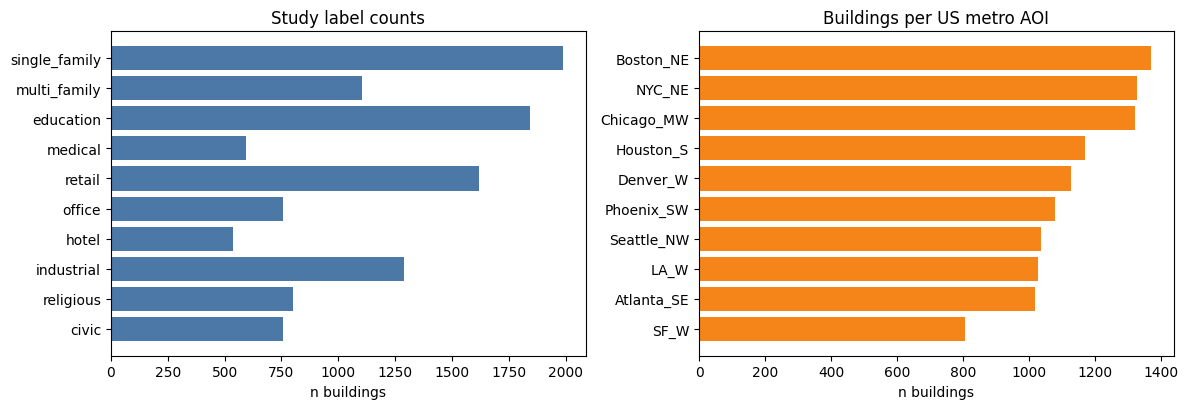

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].barh(counts.index[::-1], counts.values[::-1], color="#4C78A8")
axes[0].set_xlabel("n buildings")
axes[0].set_title("Study label counts")

reg_n = df.groupby("region").size().sort_values(ascending=True)
axes[1].barh(reg_n.index, reg_n.values, color="#F58518")
axes[1].set_xlabel("n buildings")
axes[1].set_title("Buildings per US metro AOI")

fig.tight_layout()
fig.savefig(OUT / "dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. AlphaEarth association check

Each row is one building footprint + one 64-D annual embedding (unit-length expected).


L2 norms: mean=1.0001  std=0.0020  min=0.9937  max=1.0088
null bands: 0
height fill: 94.2%
floors fill: 29.6%


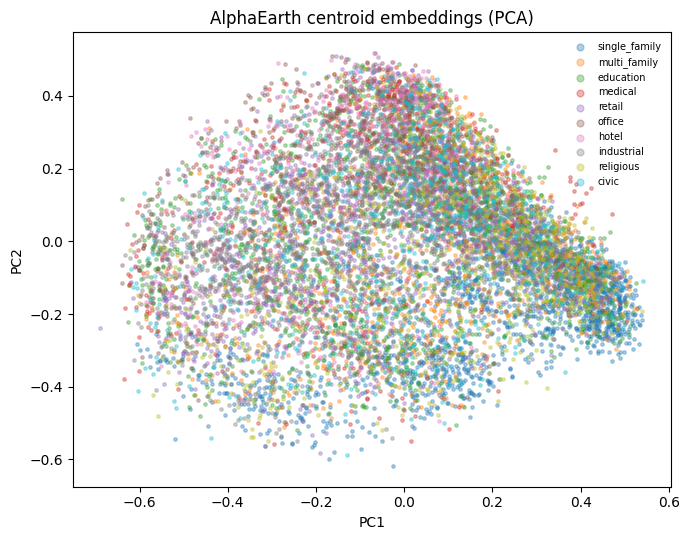

In [5]:
X = df[BANDS].to_numpy(dtype=float)
norms = np.linalg.norm(X, axis=1)
print(f"L2 norms: mean={norms.mean():.4f}  std={norms.std():.4f}  min={norms.min():.4f}  max={norms.max():.4f}")
print(f"null bands: {int(df[BANDS].isna().sum().sum())}")
print(f"height fill: {100 * df['height'].notna().mean():.1f}%")
print(f"floors fill: {100 * df['num_floors'].notna().mean():.1f}%")

# Quick PCA sketch of class separation (descriptive only)
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

enc = LabelEncoder().fit(df["label"])
y = enc.transform(df["label"])
pcs = PCA(n_components=2, random_state=42).fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 5.5))
for lab in LABEL_ORDER:
    m = df["label"].to_numpy() == lab
    ax.scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.35, label=lab)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("AlphaEarth centroid embeddings (PCA)")
ax.legend(markerscale=2, fontsize=7, frameon=False, loc="best")
fig.tight_layout()
fig.savefig(OUT / "embedding_pca_by_label.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. What's missing (vs research brief)

The brief allows footprints, land-use, cadastral, OSM, and other public datasets. **v1 uses Overture OSM-class labels + footprints + AlphaEarth only.** Everything else is tracked in `GAPS.md`.


In [6]:
gaps_df = pd.DataFrame(gaps["missing"])[["id", "item", "status", "why", "next"]]
display(gaps_df)

print("\n--- GAPS.md ---\n")
print((OUT / "GAPS.md").read_text())


,id,item,status,why,next
0,cadastral_parcels,Cadastral / parcel land-use attributes,missing,Research brief allows cadastral data; not join...,Join city/county parcel LU codes (e.g. NYC PLU...
1,zoning_landuse,Zoning / land-use layers (non-OSM),missing,No municipal zoning or NLCD/local LU attached;...,Attach zoning district or land-use raster/poly...
2,places_poi_join,Overture Places POI spatial join,missing,Schools/hospitals are sparse as building.class...,Point-in-polygon / nearest-building join for e...
3,ghs_obat,GHS-OBAT residential / non-residential weak la...,missing,Useful for global binary expansion; not in thi...,Optional weak-label track; keep separate from ...
4,street_view_vhr,Street-view / VHR image features,missing,Dataset is multi-modal-ready (WKT kept) but on...,Join GSV / satellite chips keyed by id for Pro...
5,neighbor_graph,Building-neighbor / street graph features,missing,SOTA multi-modal papers use graphs; not comput...,kNN footprint graph or OSM street network feat...
6,footprint_mean_pooling,Footprint-mean AlphaEarth pooling,missing,Current vectors are centroid-only; small build...,Mean-pool embedding image over polygon (+ opti...
7,global_south_coverage,Global / Global-South labeled coverage,missing,US metros only. Overture class fill collapses ...,Europe OSM-rich cities for transfer; Places/GH...
8,ambiguous_osm_classes,Ambiguous OSM classes as gold labels,intentionally_excluded,"class=residential, terrace, bare building=yes ...",Keep excluded from gold multi-class; optional ...
9,full_metro_extents,Full metro / state extents,missing,AOIs are compact downtown boxes for cheap quer...,Raise N_PER_CLASS and expand bboxes once pipel...



--- GAPS.md ---

# Building-type dataset — what's present vs missing

**Version:** `building_type_v1`  
**Overture release:** `2026-08-19.0`  
**Embeddings:** AlphaEarth annual 2024 (64-D centroid)

## Present

- High-precision Overture `class` → study labels (SF, MF, schools, hospitals, commercial/office, + extras)
- Building footprints (WKT) + centroids
- AlphaEarth Satellite Embedding V1 associated per building
- Geography: 10 US metro compact AOIs (not national / not global)

### Label counts

| label | n |
|---|---:|
| `single_family` | 1987 |
| `education` | 1840 |
| `retail` | 1616 |
| `industrial` | 1287 |
| `multi_family` | 1102 |
| `religious` | 802 |
| `civic` | 757 |
| `office` | 756 |
| `medical` | 594 |
| `hotel` | 539 |

## Missing (tracked gaps)

| ID | Item | Status | Why / next |
|---|---|---|---|
| `cadastral_parcels` | Cadastral / parcel land-use attributes | missing | Research brief allows cadastral data; not joined. Would improve commercial vs residential in US c

## 5. How to use later

```python
import pandas as pd
df = pd.read_parquet("outputs/building_type_dataset/dataset.parquet")
bands = [f"A{i:02d}" for i in range(64)]
X, y = df[bands].to_numpy(), df["label"]
# Binary residential:
y_res = df["y_res"]
# Research-brief rollup (commercial ∪ office):
y_brief = df["brief_category"]
```

| File | Use |
|---|---|
| `dataset.parquet` | Training / eval (meta + WKT + embeddings) |
| `dataset_browse.csv` | Quick inspection without vectors |
| `labels_only.parquet` | Footprints + labels before EE join |
| `manifest.json` | Provenance / taxonomy |
| `gaps.json` / `GAPS.md` | Missing modalities & next joins |

**Next modeling notebooks** can point at this path instead of resampling Overture.


In [7]:
print("Canonical dataset root:", OUT)
print("n =", len(df))
print("Ready for downstream classifiers / LORO / carbon archetypes.")


Canonical dataset root: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_type_dataset
n = 11280
Ready for downstream classifiers / LORO / carbon archetypes.
